<a href="https://colab.research.google.com/github/sophiannunez18/DSC_110/blob/main/ML_Model_Building.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# This was used to import our dataset as pd
import pandas as pd
from sklearn.linear_model import LinearRegression

In [2]:
# This was used to create a table with the variable age and to contain the five ages listed
X = pd.DataFrame({'age': [20, 30, 40, 50, 60]})

In [3]:
# This was used to show the first 5 rows of our dataset which we can see in the table
X.head()

,age
0,20
1,30
2,40
3,50
4,60


In [4]:
# This was used to create a list of the following number and make it into a variable known as y
y = [110, 115, 120, 125, 130]

In [5]:
# This was used to make a linear regression within our data, we wanted to see how ages and blood pressure are related to each other
lr = LinearRegression()
lr.fit(X,y)

LinearRegression()

In [6]:
# This was used to use our linear regression to predict the blood pressures for the ages listed

ages_to_predict = pd.DataFrame({'age': [10, 45, 55, 90]})
predictions = lr.predict(ages_to_predict)
print(predictions)

[105.  122.5 127.5 145. ]


In [7]:
# This was used to print each prediction from above and also have it be to 2 decimal places

for p in predictions:
  print(f"{p:.2f}")

105.00
122.50
127.50
145.00


In [8]:
#Assuming y is a binary variables that's 0 or 1 (has hypertension or no)

y = [0, 0, 0, 1, 1]
lr.fit(X, y)
predictions = lr.predict(ages_to_predict)

for p in predictions:
  print(f"{p:.2f}")

-0.50
0.55
0.85
1.90


In [10]:
#Logistic regression, this was used to code and train a logistic regression and then used it to predict the probability of an outcome happening
from sklearn.linear_model import LogisticRegression
import numpy as np

lr = LogisticRegression()
lr.fit(X, y)

probabilites = lr.predict_proba(ages_to_predict)

for p in probabilites[:, 1]:
  print(f"{p:.2f}")

0.00
0.50
1.00
1.00


In [11]:
# This was used to code a logistic model using an outcome that is either year or no used by 0,1

y = [0, 0, 1, 1, 0]

lr.fit(X, y)

probabilites = lr.predict_proba(ages_to_predict)

for p in probabilites[:, 1]:
  print(f"{p:.2f}")

0.15
0.44
0.55
0.85


In [12]:
# this was used to see the first 5 rows of our age to predict


ages_to_predict.head()

,age
0,10
1,45
2,55
3,90


In [13]:
#Descision tree

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt.fit(X, y)

probabilites = dt.predict(ages_to_predict)

for p in probabilites:
  print(f"{p:.2f}")

0.00
1.00
1.00
0.00


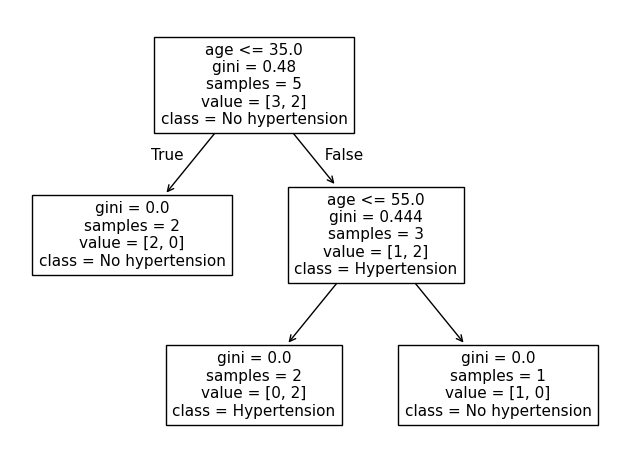

In [20]:
# This is used to display our decision tree diagram, it was used to predict if a patient has hypertension based on their age

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plot_tree(dt,
          feature_names = ['age'],
          class_names = ['No hypertension', 'Hypertension'])
plt.tight_layout()
plt.show()

Part 2: Applying these ML Models to our own NHANES data

In [21]:
# This was used to build different prediction models and see how they are performed

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [23]:
# This was used import four different dataset and put them with different variables


X_train = pd.read_csv("https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_train.csv")
X_test = pd.read_csv("https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_test.csv")
y_train = pd.read_csv("https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_train.csv")
y_test = pd.read_csv ("https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_test.csv")

In [24]:
# This was used to show us the size of our dataset, it shows the number of rows and columns

X_train.shape

(6018, 15)

In [25]:
# This shows us the first five rows of our y_train dataset

y_train.head()

,has_diabetes
0,0
1,0
2,0
3,1
4,0


In [27]:
# This was used to convert our y train and test datasets into a single list of values

y_train = y_train.squeeze()
y_test = y_test.squeeze()

In [28]:
#Logistic regression

lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

In [29]:
#Pick one patient from the test dataset

patient = X_test.iloc[[243]]

In [30]:
# This shows the one patient we picked from above

patient

,age,bmi,height_cm,systolic_bp,gender_Male,race_ethnicity_Black,race_ethnicity_Mexican American,race_ethnicity_Other,race_ethnicity_Other Hispanic,race_ethnicity_White,education_College grad,education_Do not know,education_High school,education_Less than 9th,education_Some college
243,0.776425,1.479961,-0.391115,1.444984,False,False,False,False,False,True,False,False,True,False,False


In [31]:
# This was used to show the values of a specific row based on the number 243
y_test.iloc[243]

np.int64(1)

In [32]:
# Using Logistic Regression model to see if this paitents was predicted accurately or not

lr.predict(patient)[0]

np.int64(0)

In [ ]:
# predict the whole test dataset

y_pred = lr.predict(X_test)

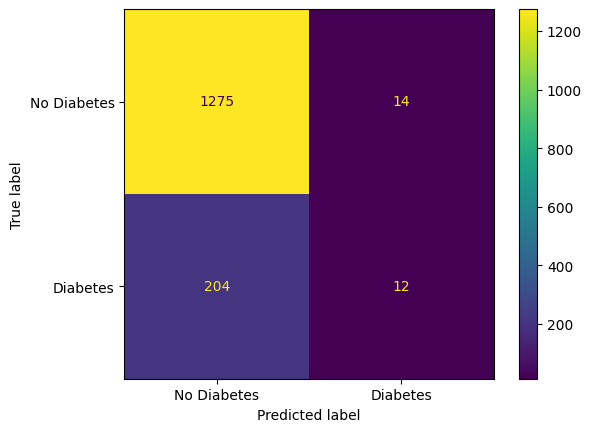

In [34]:
# This was used to predict if people had diabetes and then we created a confusion matrix to show us how accruate the preidictions are

y_pred = lr.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels= ['No Diabetes', 'Diabetes'])
plt.show()

In [35]:
# applying decision tree to our dataset

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [36]:
# Testing on our one patient sample

dt.predict(patient)[0]

np.int64(0)

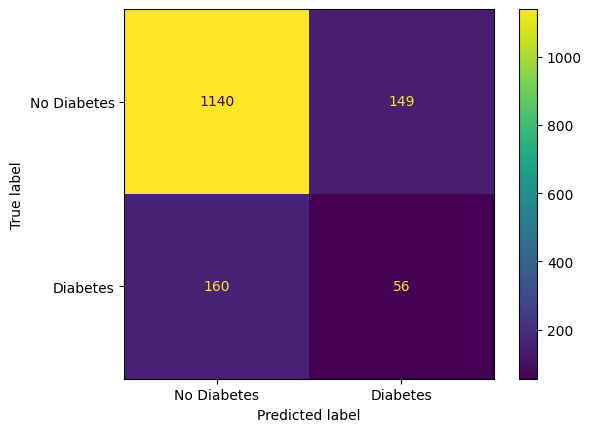

In [38]:
# Apply Decision Tree model to the test dataset
y_pred = dt.predict(X_test)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels = ['No Diabetes', 'Diabetes']
)
plt.show()

Random Forest

In [39]:
# This code was used to create a random forest model and then use it to predict

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf.predict(patient)[0]

np.int64(1)

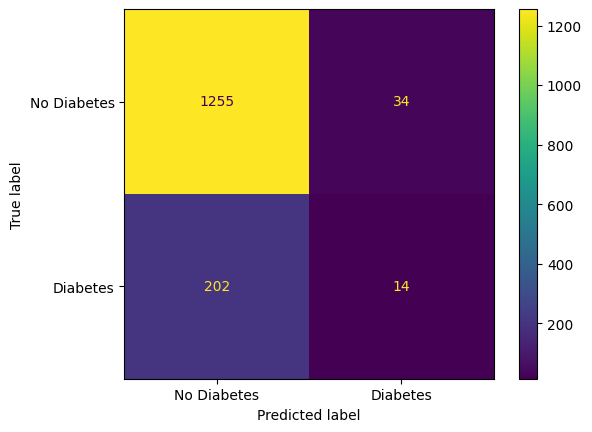

In [40]:
# This was used to see how well our random forest model was at predicting diabetes

y_pred = rf.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels = ['No Diabetes', 'Diabetes']
)
plt.show()

XG Boost

In [41]:
# This was used to create an XG boost model and then also using it to make predictions for diabetes
xgb = XGBClassifier(random_state=42)
xgb.fit(X_train, y_train)
xgb.predict(patient)[0]

np.int64(0)

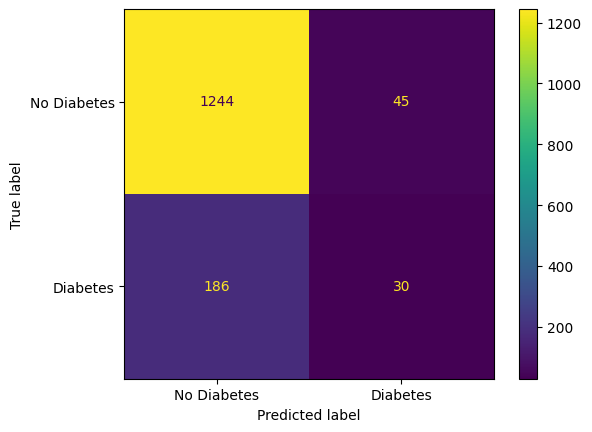

In [43]:
# This was used to see how well our XG boost was at predicting diabetes
y_pred = xgb.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels = ['No Diabetes', 'Diabetes']
)
plt.show()

Nueral Network

In [44]:
# This was used to create a neural network to predict if someone has diabetes
nn = MLPClassifier(random_state=42, max_iter=500)
nn.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(max_iter=500, random_state=42)

In [45]:
# This was used to predict whether a specific patient has diabetes
nn.predict(patient)[0]

np.int64(0)

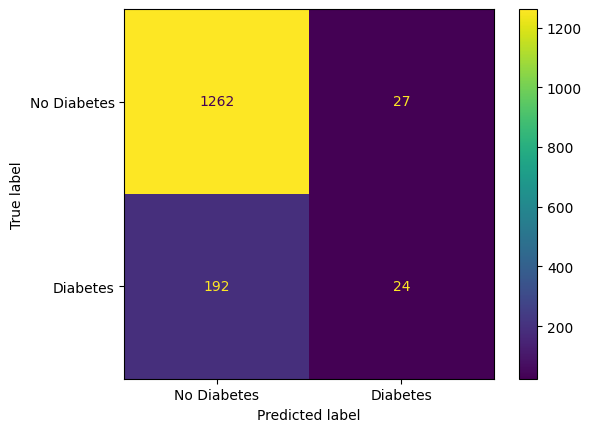

In [46]:
# This was used to see how well our neural network predicts diabetes with our confusion matrix

y_pred = nn.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels = ['No Diabetes', 'Diabetes']
)
plt.show()